# Customer Analysis for Retail

### Retail Analytics Case Study — Jupyter Notebook

**Objective:** Merge customer, transaction and product-hierarchy data and answer the business questions provided in the case study.

The case study asks for customer/transaction analysis, summary statistics, visualizations, and specific business metrics. The source data contains three CSV files:
- `Customer.csv`
- `Transactions.csv`
- `prod_cat_info.csv`

> **Note:** Transaction and DOB date fields contain mixed date-string formats, so dates are parsed with `format='mixed'` and `dayfirst=True`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11


## 1. Load the datasets

In [2]:
transactions = pd.read_csv('data/Transactions.csv')
customer = pd.read_csv('data/Customer.csv')
prod_cat_info = pd.read_csv('data/prod_cat_info.csv')

print('Transactions:', transactions.shape)
print('Customer:', customer.shape)
print('Product hierarchy:', prod_cat_info.shape)

display(transactions.head())
display(customer.head())
display(prod_cat_info.head())


Transactions: (23053, 10)
Customer: (5647, 4)
Product hierarchy: (23, 4)


,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
0,80712190438,270351,28-02-2014,1,1,-5,-772,405.30,"-4,265.30",e-Shop
1,29258453508,270384,27-02-2014,5,3,-5,-1497,785.92,"-8,270.92",e-Shop
2,51750724947,273420,24-02-2014,6,5,-2,-791,166.11,"-1,748.11",TeleShop
3,93274880719,271509,24-02-2014,11,6,-3,-1363,429.35,"-4,518.35",e-Shop
4,51750724947,273420,23-02-2014,6,5,-2,-791,166.11,"-1,748.11",TeleShop


,customer_Id,DOB,Gender,city_code
0,268408,02-01-1970,M,4.00
1,269696,07-01-1970,F,8.00
2,268159,08-01-1970,F,8.00
3,270181,10-01-1970,F,2.00
4,268073,11-01-1970,M,1.00


,prod_cat_code,prod_cat,prod_sub_cat_code,prod_subcat
0,1,Clothing,4,Mens
1,1,Clothing,1,Women
2,1,Clothing,3,Kids
3,2,Footwear,1,Mens
4,2,Footwear,3,Women


## 2. Inspect and prepare the data

In [3]:
# Convert date columns. The source contains mixed separators/formats.
transactions['tran_date'] = pd.to_datetime(
    transactions['tran_date'], format='mixed', dayfirst=True
)
customer['DOB'] = pd.to_datetime(
    customer['DOB'], format='mixed', dayfirst=True
)

print('Missing values — Transactions')
display(transactions.isna().sum().to_frame('Missing'))

print('Missing values — Customer')
display(customer.isna().sum().to_frame('Missing'))

print('Missing values — Product hierarchy')
display(prod_cat_info.isna().sum().to_frame('Missing'))

print('Duplicate rows:')
print('Transactions:', transactions.duplicated().sum())
print('Customer:', customer.duplicated().sum())
print('Product hierarchy:', prod_cat_info.duplicated().sum())


Missing values — Transactions


,Missing
transaction_id,0
cust_id,0
tran_date,0
prod_subcat_code,0
prod_cat_code,0
Qty,0
Rate,0
Tax,0
total_amt,0
Store_type,0


Missing values — Customer


,Missing
customer_Id,0
DOB,0
Gender,2
city_code,2


Missing values — Product hierarchy


,Missing
prod_cat_code,0
prod_cat,0
prod_sub_cat_code,0
prod_subcat,0


Duplicate rows:
Transactions: 13
Customer: 0
Product hierarchy: 0


## 3. Merge the datasets as `Customer_Final`

The case study requires keeping customers who have transactions. Therefore, the transaction table is used as the base and an **inner join** is used with Customer. Product information is then joined using product category and sub-category codes.



In [4]:
Customer_Final = (
    transactions
    .merge(
        customer,
        left_on='cust_id',
        right_on='customer_Id',
        how='inner'
    )
    .merge(
        prod_cat_info,
        left_on=['prod_cat_code', 'prod_subcat_code'],
        right_on=['prod_cat_code', 'prod_sub_cat_code'],
        how='left'
    )
)

print('Customer_Final shape:', Customer_Final.shape)
print('Unique customers:', Customer_Final['customer_Id'].nunique())
print('Unique transactions:', Customer_Final['transaction_id'].nunique())
display(Customer_Final.head())


Customer_Final shape: (23053, 17)
Unique customers: 5506
Unique transactions: 20878


,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,2014-02-28,1,1,-5,-772,405.30,"-4,265.30",e-Shop,270351,1981-09-26,M,5.00,Clothing,1,Women
1,29258453508,270384,2014-02-27,5,3,-5,-1497,785.92,"-8,270.92",e-Shop,270384,1973-05-11,F,8.00,Electronics,5,Computers
2,51750724947,273420,2014-02-24,6,5,-2,-791,166.11,"-1,748.11",TeleShop,273420,1992-07-27,M,8.00,Books,6,DIY
3,93274880719,271509,2014-02-24,11,6,-3,-1363,429.35,"-4,518.35",e-Shop,271509,1981-06-08,M,3.00,Home and kitchen,11,Bath
4,51750724947,273420,2014-02-23,6,5,-2,-791,166.11,"-1,748.11",TeleShop,273420,1992-07-27,M,8.00,Books,6,DIY


## 4. Summary report

### 4.1 Column names and data types


In [5]:
summary_dtypes = pd.DataFrame({
    'Column': Customer_Final.columns,
    'Data Type': Customer_Final.dtypes.astype(str).values
})
display(summary_dtypes)


,Column,Data Type
0,transaction_id,int64
1,cust_id,int64
2,tran_date,datetime64[ns]
3,prod_subcat_code,int64
4,prod_cat_code,int64
5,Qty,int64
6,Rate,int64
7,Tax,float64
8,total_amt,float64
9,Store_type,object


### 4.2 Top 10 and bottom 10 observations

In [6]:
print('Top 10 observations')
display(Customer_Final.head(10))

print('Bottom 10 observations')
display(Customer_Final.tail(10))


Top 10 observations


,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
0,80712190438,270351,2014-02-28,1,1,-5,-772,405.30,"-4,265.30",e-Shop,270351,1981-09-26,M,5.00,Clothing,1,Women
1,29258453508,270384,2014-02-27,5,3,-5,-1497,785.92,"-8,270.92",e-Shop,270384,1973-05-11,F,8.00,Electronics,5,Computers
2,51750724947,273420,2014-02-24,6,5,-2,-791,166.11,"-1,748.11",TeleShop,273420,1992-07-27,M,8.00,Books,6,DIY
3,93274880719,271509,2014-02-24,11,6,-3,-1363,429.35,"-4,518.35",e-Shop,271509,1981-06-08,M,3.00,Home and kitchen,11,Bath
4,51750724947,273420,2014-02-23,6,5,-2,-791,166.11,"-1,748.11",TeleShop,273420,1992-07-27,M,8.00,Books,6,DIY
5,97439039119,272357,2014-02-23,8,3,-2,-824,173.04,"-1,821.04",TeleShop,272357,1982-10-09,F,6.00,Electronics,8,Personal Appliances
6,45649838090,273667,2014-02-22,11,6,-1,-1450,152.25,"-1,602.25",e-Shop,273667,1981-05-29,M,9.00,Home and kitchen,11,Bath
7,22643667930,271489,2014-02-22,12,6,-1,-1225,128.62,"-1,353.62",TeleShop,271489,1971-04-21,M,9.00,Home and kitchen,12,Tools
8,79792372943,275108,2014-02-22,3,1,-3,-908,286.02,"-3,010.02",MBR,275108,1971-11-04,F,8.00,Clothing,3,Kids
9,50076728598,269014,2014-02-21,8,3,-4,-581,244.02,"-2,568.02",e-Shop,269014,1979-11-27,F,3.00,Electronics,8,Personal Appliances


Bottom 10 observations


,transaction_id,cust_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,customer_Id,DOB,Gender,city_code,prod_cat,prod_sub_cat_code,prod_subcat
23043,49882891062,271982,2011-01-25,10,5,4,1330,558.60,"5,878.60",e-Shop,271982,1976-08-10,M,8.00,Books,10,Non-Fiction
23044,14787475597,273982,2011-01-25,4,3,5,969,508.73,"5,353.73",e-Shop,273982,1991-10-12,M,4.00,Electronics,4,Mobiles
23045,50691119572,273031,2011-01-25,6,5,1,1148,120.54,"1,268.54",TeleShop,273031,1980-01-17,F,8.00,Books,6,DIY
23046,40893803228,272049,2011-01-25,11,6,3,1077,339.25,"3,570.26",e-Shop,272049,1975-06-28,F,6.00,Home and kitchen,11,Bath
23047,30856003613,266866,2011-01-25,4,2,2,444,93.24,981.24,TeleShop,266866,1974-04-18,M,4.00,Footwear,4,Kids
23048,94340757522,274550,2011-01-25,12,5,1,1264,132.72,"1,396.72",e-Shop,274550,1972-02-21,M,7.00,Books,12,Academic
23049,89780862956,270022,2011-01-25,4,1,1,677,71.08,748.09,e-Shop,270022,1984-04-27,M,9.00,Clothing,4,Mens
23050,85115299378,271020,2011-01-25,2,6,4,1052,441.84,"4,649.84",MBR,271020,1976-06-20,M,8.00,Home and kitchen,2,Furnishing
23051,72870271171,270911,2011-01-25,11,5,3,1142,359.73,"3,785.73",TeleShop,270911,1970-05-22,M,2.00,Books,11,Children
23052,77960931771,271961,2011-01-25,11,5,1,447,46.94,493.94,TeleShop,271961,1982-01-15,M,1.00,Books,11,Children


### 4.3 Five-number summary for continuous/numeric variables

Five-number summary = **minimum, Q1, median, Q3, maximum**.


In [7]:
numeric_cols = Customer_Final.select_dtypes(include=np.number).columns

five_number_summary = Customer_Final[numeric_cols].describe().T[
    ['min', '25%', '50%', '75%', 'max']
].rename(columns={
    '25%': 'Q1',
    '50%': 'Median',
    '75%': 'Q3'
})

display(five_number_summary)


,min,Q1,Median,Q3,max
transaction_id,"3,268,991.00","24,938,639,453.00","50,093,131,361.00","75,329,995,679.00","99,987,549,630.00"
cust_id,"266,783.00","268,935.00","270,980.00","273,114.00","275,265.00"
prod_subcat_code,1.00,3.00,5.00,10.00,12.00
prod_cat_code,1.00,2.00,4.00,5.00,6.00
Qty,-5.00,1.00,3.00,4.00,5.00
Rate,"-1,499.00",312.00,710.00,"1,109.00","1,500.00"
Tax,7.35,98.28,199.08,365.71,787.50
total_amt,"-8,270.92",762.45,"1,754.74","3,569.15","8,287.50"
customer_Id,"266,783.00","268,935.00","270,980.00","273,114.00","275,265.00"
city_code,1.00,3.00,5.00,8.00,10.00


### 4.4 Frequency tables for categorical variables

Variables represented as categories in the merged dataset include gender, city code, store type, product category and product sub-category.


In [8]:
categorical_cols = [
    'Gender', 'city_code', 'Store_type', 'prod_cat', 'prod_subcat'
]

for col in categorical_cols:
    print(f'Frequency table — {col}')
    display(Customer_Final[col].value_counts(dropna=False).to_frame('Frequency'))


Frequency table — Gender


,Frequency
Gender,
M,11811
F,11233
NaN,9


Frequency table — city_code


,Frequency
city_code,
4.00,2422
3.00,2411
5.00,2360
7.00,2356
10.00,2333
8.00,2330
2.00,2270
1.00,2258
9.00,2178


Frequency table — Store_type


,Frequency
Store_type,
e-Shop,9311
MBR,4661
Flagship store,4577
TeleShop,4504


Frequency table — prod_cat


,Frequency
prod_cat,
Books,6069
Electronics,4898
Home and kitchen,4129
Footwear,2999
Clothing,2960
Bags,1998


Frequency table — prod_subcat


,Frequency
prod_subcat,
Women,3048
Mens,2912
Kids,1997
Tools,1062
Fiction,1043
Kitchen,1037
Children,1035
Mobiles,1031
Comics,1031


## 5. Histograms and frequency-bar charts

The case study asks for histograms for continuous variables and frequency bars for categorical variables.




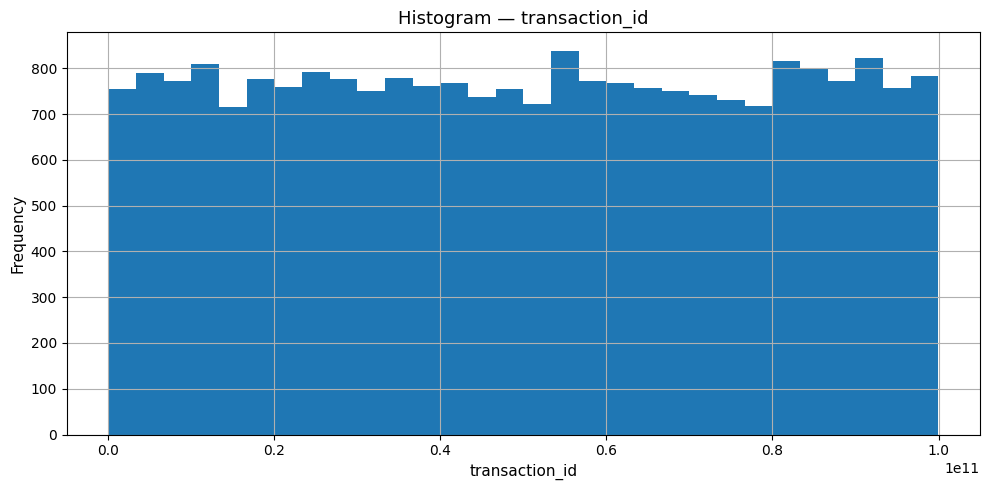

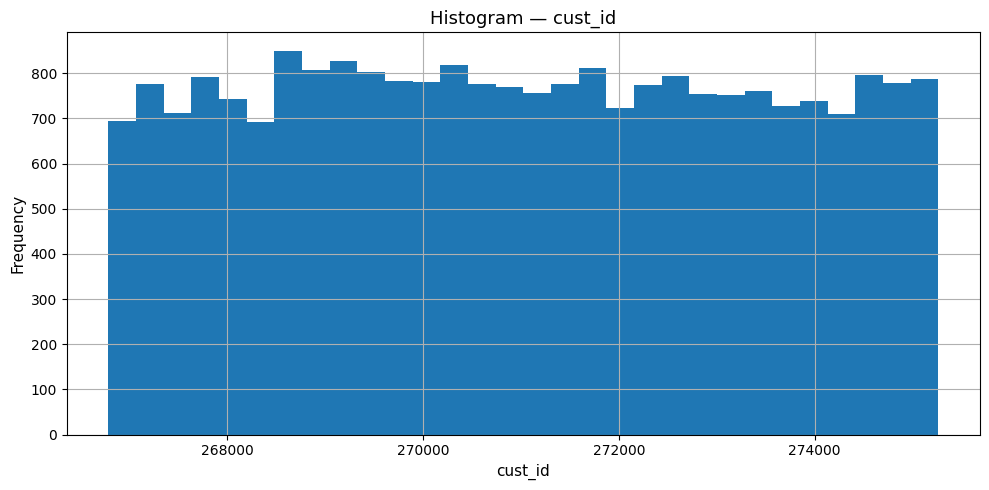

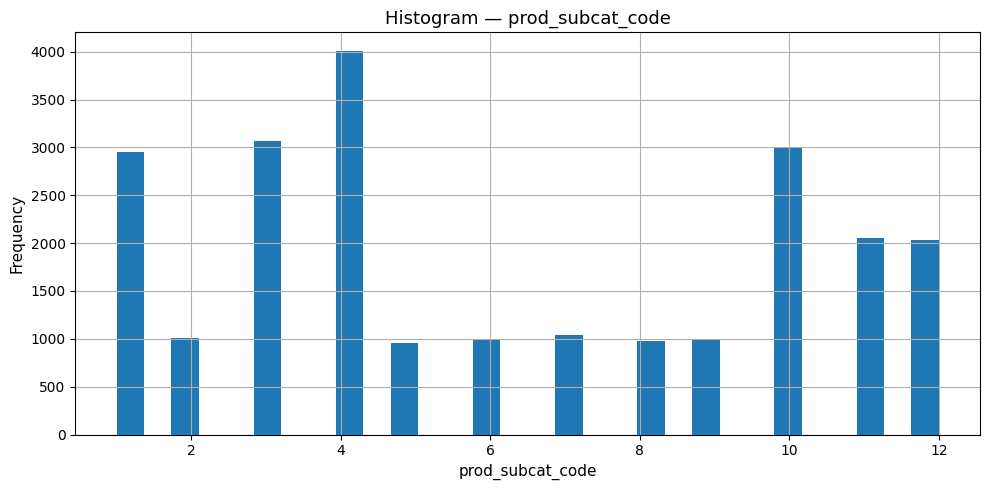

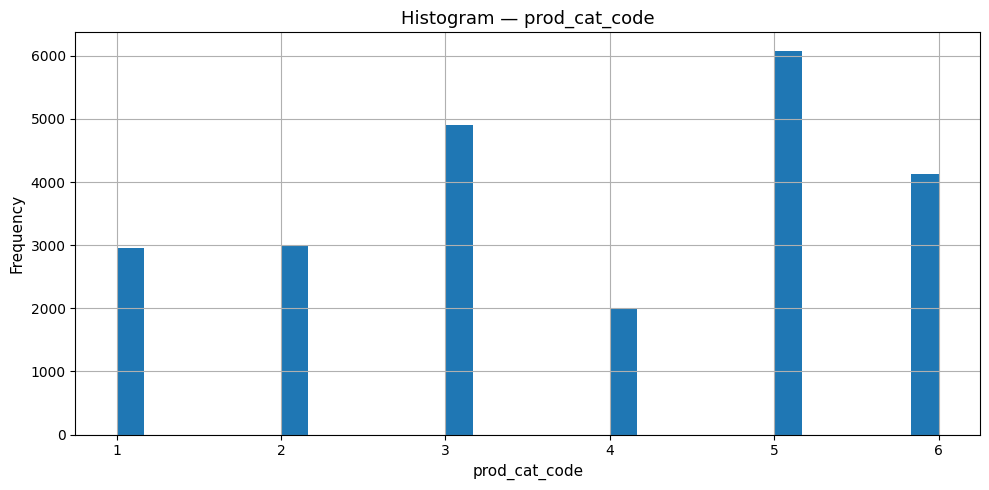

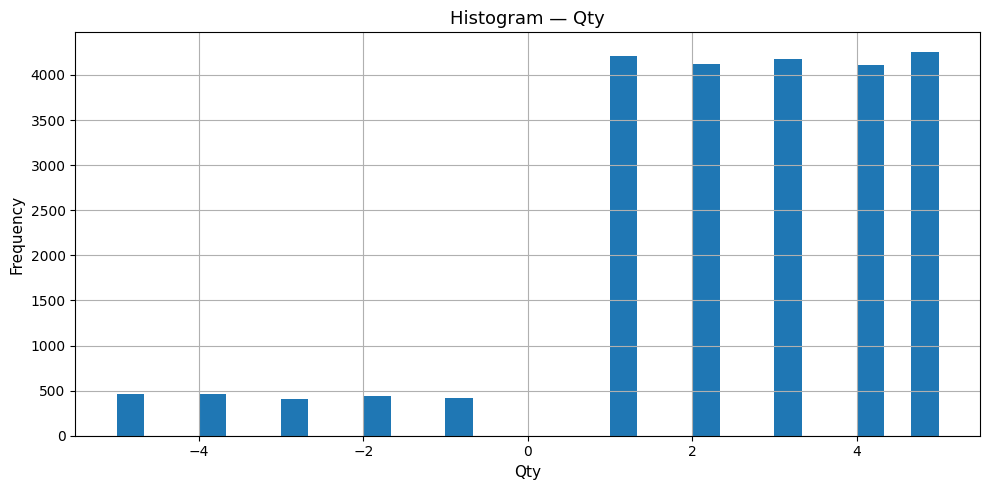

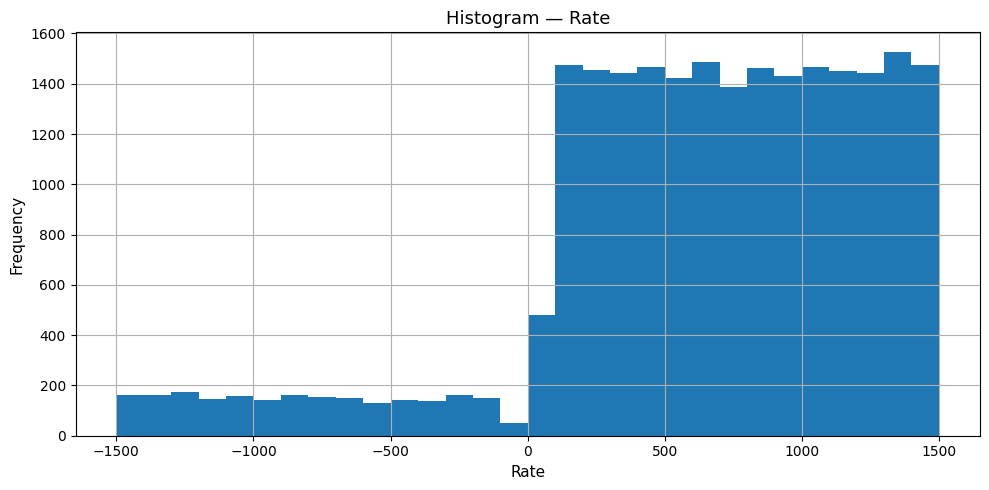

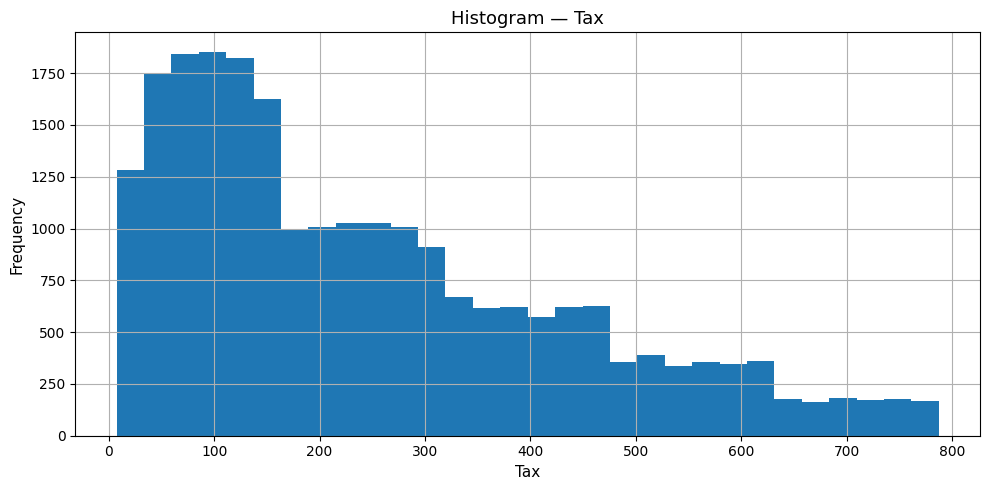

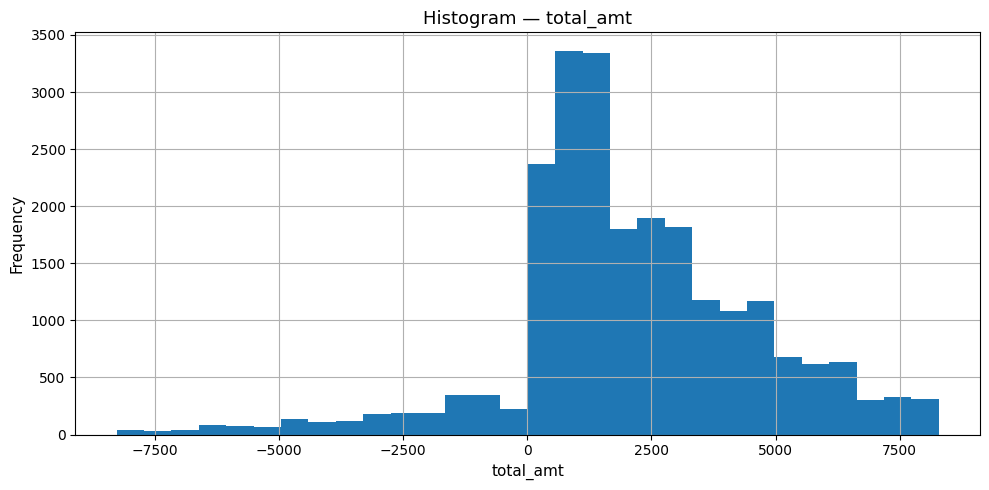

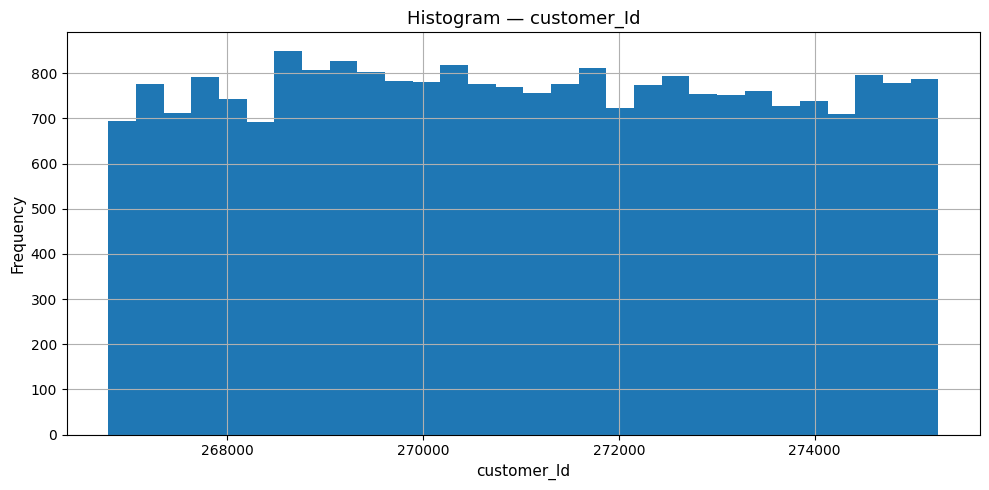

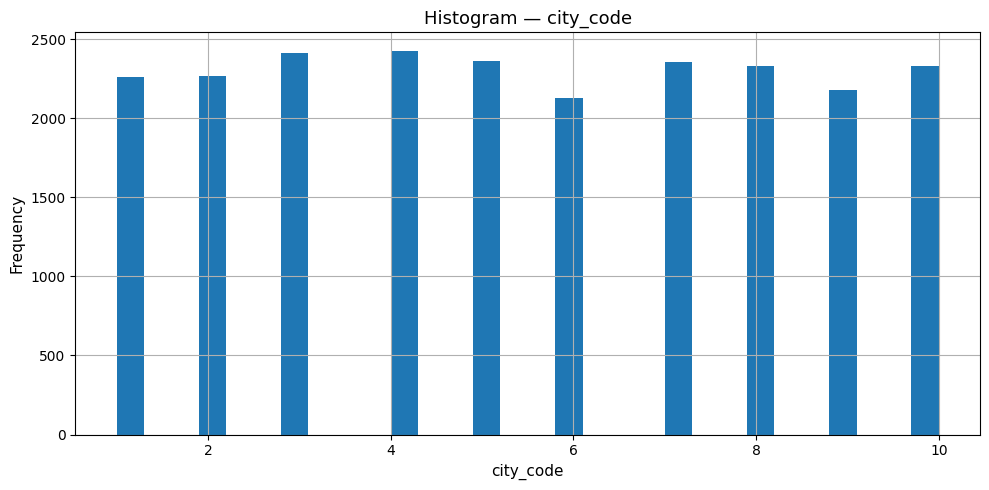

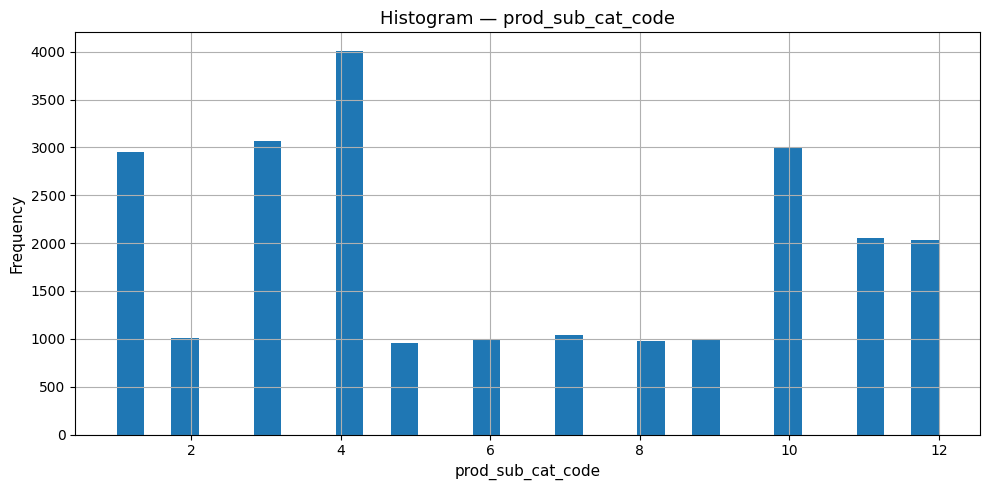

In [9]:
# Histograms for numeric variables
for col in numeric_cols:
    plt.figure()
    Customer_Final[col].hist(bins=30)
    plt.title(f'Histogram — {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
     plt.show()


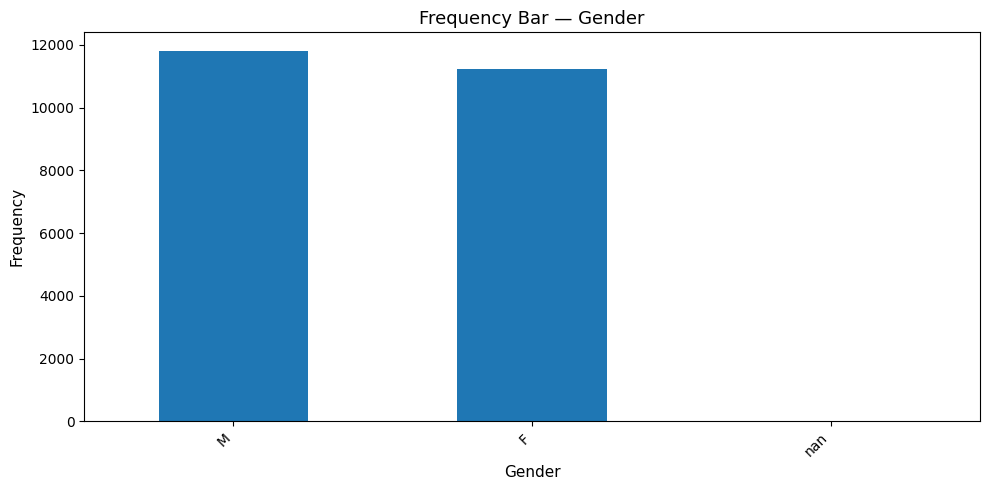

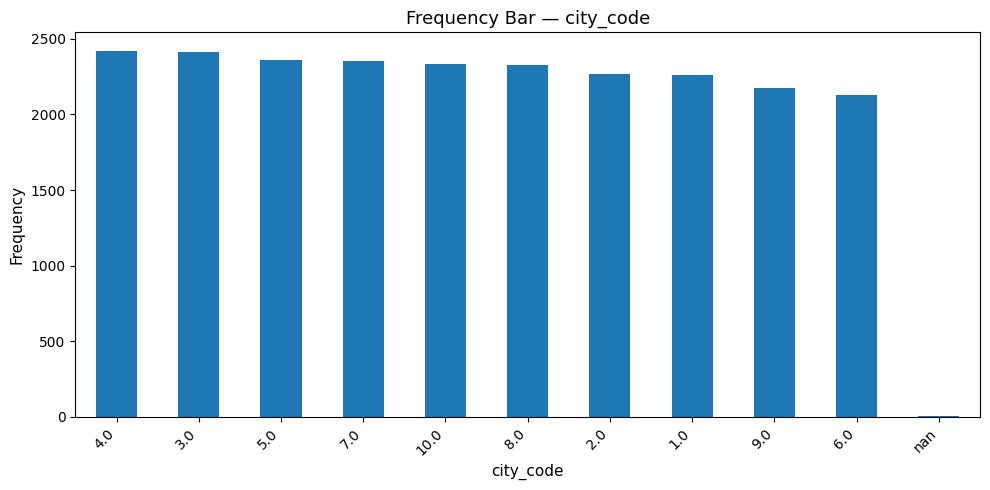

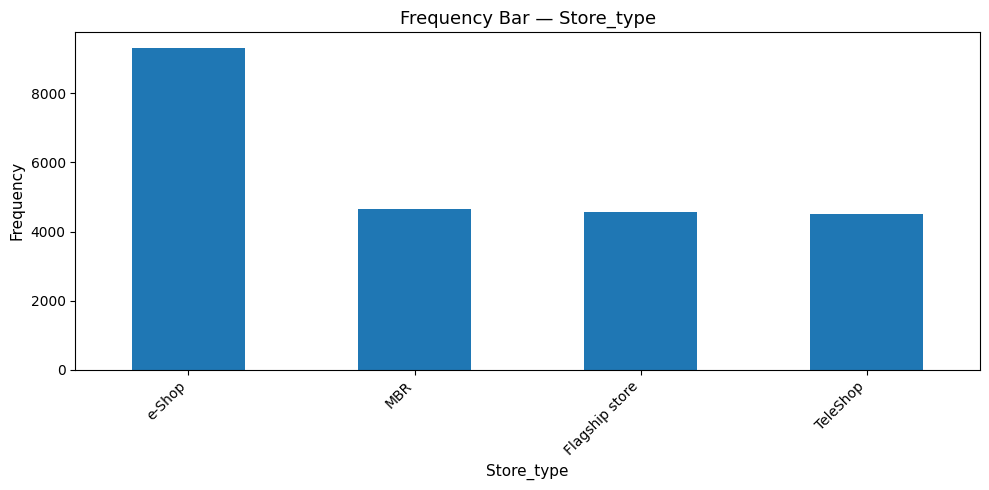

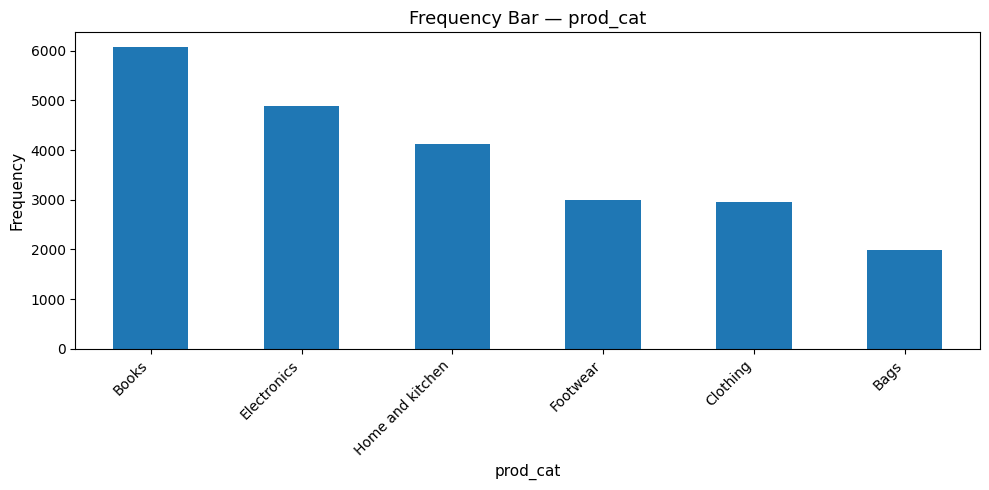

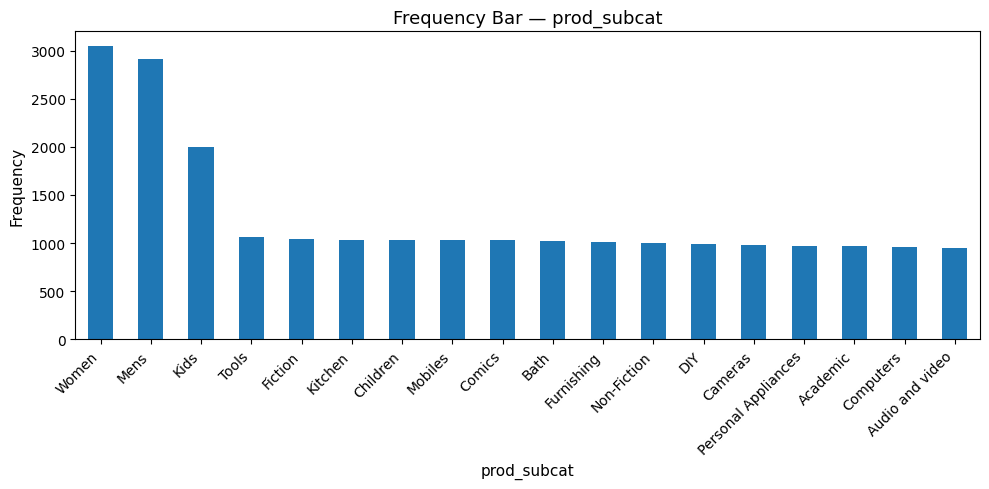

In [10]:
# Frequency bars for categorical variables
for col in categorical_cols:
    counts = Customer_Final[col].value_counts(dropna=False)
    plt.figure()
    counts.plot(kind='bar')
    plt.title(f'Frequency Bar — {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


## 6. Business Questions

### 6.1 Time period of available transaction data


In [11]:
start_date = Customer_Final['tran_date'].min()
end_date = Customer_Final['tran_date'].max()

print(f'Transaction period: {start_date:%d-%b-%Y} to {end_date:%d-%b-%Y}')


Transaction period: 25-Jan-2011 to 28-Feb-2014


### 6.2 Count of transactions with negative total amount

In [12]:
negative_transaction_count = (Customer_Final['total_amt'] < 0).sum()

print('Transactions with negative total amount:', negative_transaction_count)


Transactions with negative total amount: 2177


### 6.3 Product categories popular among females vs males

We compare the number of transaction records by gender and product category.


Gender,F,M
prod_cat,,
Bags,994,1004
Books,2949,3116
Clothing,1439,1518
Electronics,2328,2570
Footwear,1529,1469
Home and kitchen,1994,2134


Category with maximum transaction records for females: Books
Category with maximum transaction records for males: Books


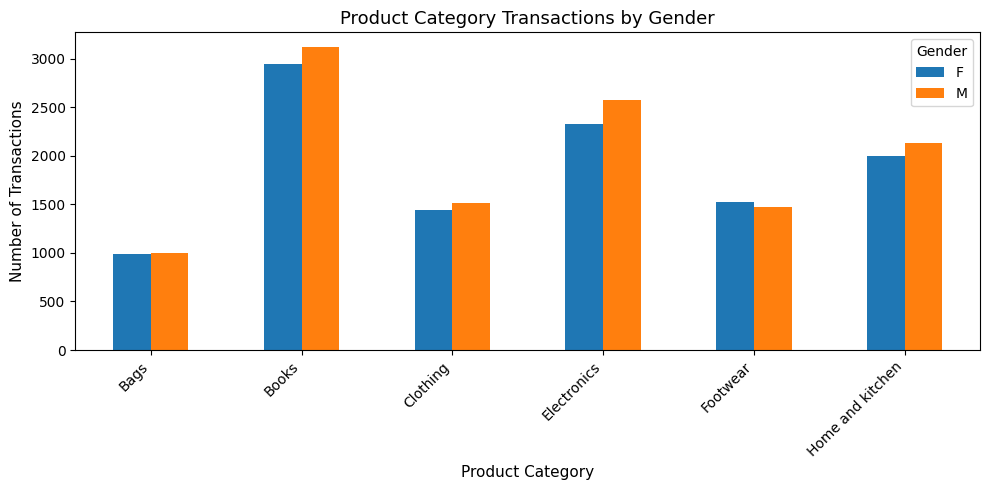

In [13]:
gender_category = pd.crosstab(
    Customer_Final['prod_cat'],
    Customer_Final['Gender']
)

display(gender_category)

print('Category with maximum transaction records for females:',
      gender_category['F'].idxmax())
print('Category with maximum transaction records for males:',
      gender_category['M'].idxmax())

gender_category.plot(kind='bar')
plt.title('Product Category Transactions by Gender')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### 6.4 City code with maximum customers and percentage of customers

In [14]:
customer_city = (
    Customer_Final.groupby('city_code')['customer_Id']
    .nunique()
    .sort_values(ascending=False)
)

max_city = customer_city.idxmax()
max_city_customers = customer_city.max()
total_customers = Customer_Final['customer_Id'].nunique()
max_city_percentage = max_city_customers / total_customers * 100

display(customer_city.to_frame('Unique Customers'))

print(f'Maximum customer city code: {int(max_city)}')
print(f'Customers in city code {int(max_city)}: {max_city_customers}')
print(f'Percentage of customers: {max_city_percentage:.2f}%')


,Unique Customers
city_code,
3.00,576
5.00,570
4.00,569
7.00,563
8.00,551
2.00,546
10.00,546
1.00,535
9.00,532


Maximum customer city code: 3
Customers in city code 3: 576
Percentage of customers: 10.46%


### 6.5 Store type selling maximum products by value and quantity

Here, **value** is measured using `total_amt` and **quantity** using `Qty`, as supplied in the transaction dataset.


In [15]:
store_summary = (
    Customer_Final.groupby('Store_type')
    .agg(
        Total_Value=('total_amt', 'sum'),
        Total_Quantity=('Qty', 'sum')
    )
    .sort_values('Total_Value', ascending=False)
)

display(store_summary)

print('Maximum value:', store_summary['Total_Value'].idxmax())
print('Maximum quantity:', store_summary['Total_Quantity'].idxmax())


,Total_Value,Total_Quantity
Store_type,,
e-Shop,"19,824,816.05",22763
Flagship store,"9,715,688.19",11133
MBR,"9,674,486.05",11194
TeleShop,"9,364,781.07",10984


Maximum value: e-Shop
Maximum quantity: e-Shop


### 6.6 Total amount earned from Electronics and Clothing in Flagship Stores


In [16]:
flagship_ec = Customer_Final[
    (Customer_Final['Store_type'] == 'Flagship store') &
    (Customer_Final['prod_cat'].isin(['Electronics', 'Clothing']))
]

flagship_category_amount = flagship_ec.groupby('prod_cat')['total_amt'].sum()
display(flagship_category_amount.to_frame('Total Amount'))

print('Combined amount:',
      f"{flagship_category_amount.sum():,.2f}")


,Total Amount
prod_cat,
Clothing,"1,194,423.23"
Electronics,"2,215,136.04"


Combined amount: 3,409,559.27


### 6.7 Total amount earned from Male customers under Electronics


In [17]:
male_electronics_amount = Customer_Final[
    (Customer_Final['Gender'] == 'M') &
    (Customer_Final['prod_cat'] == 'Electronics')
]['total_amt'].sum()

print(f'Male customers — Electronics total amount: {male_electronics_amount:,.2f}')


Male customers — Electronics total amount: 5,703,109.42


### 6.8 Customers with more than 10 unique transactions after removing negative transactions

All rows having a negative `total_amt` are removed first. The remaining data is grouped by customer and unique transaction IDs are counted.


In [18]:
positive_transactions = Customer_Final[
    Customer_Final['total_amt'] >= 0
].copy()

unique_txn_per_customer = (
    positive_transactions.groupby('cust_id')['transaction_id']
    .nunique()
)

customers_more_than_10 = (unique_txn_per_customer > 10).sum()

print('Customers with more than 10 unique transactions:',
      customers_more_than_10)


Customers with more than 10 unique transactions: 6


### 6.9 Customers aged 25–35

Age is calculated at the time of each transaction:

`Age = (Transaction Date - DOB) / 365.25`

The range is treated inclusively: **25 ≤ age ≤ 35**.


In [19]:
Customer_Final['Age'] = (
    (Customer_Final['tran_date'] - Customer_Final['DOB']).dt.days / 365.25
)

age_25_35 = Customer_Final[
    Customer_Final['Age'].between(25, 35, inclusive='both')
].copy()

print('Transaction records for customers aged 25–35:', len(age_25_35))
print('Unique customers aged 25–35:', age_25_35['customer_Id'].nunique())


Transaction records for customers aged 25–35: 9940
Unique customers aged 25–35: 2814


#### 6.9(a) Total amount spent on Electronics and Books

In [20]:
age_category_spend = (
    age_25_35[age_25_35['prod_cat'].isin(['Electronics', 'Books'])]
    .groupby('prod_cat')['total_amt']
    .sum()
)

display(age_category_spend.to_frame('Total Amount Spent'))


,Total Amount Spent
prod_cat,
Books,"5,478,976.75"
Electronics,"4,616,641.38"


#### 6.9(b) Total amount spent from 1-Jan-2014 to 1-Mar-2014

In [21]:
period_spend = age_25_35[
    age_25_35['tran_date'].between(
        pd.Timestamp('2014-01-01'),
        pd.Timestamp('2014-03-01'),
        inclusive='both'
    )
]['total_amt'].sum()

print(f'Total amount spent from 01-Jan-2014 to 01-Mar-2014: {period_spend:,.2f}')


Total amount spent from 01-Jan-2014 to 01-Mar-2014: 995,938.71


## 7. Final Answers — Business Summary

The following cell prints the key answers together so the case study can be reviewed quickly.


In [22]:
print('1. Merge: Inner join from transactions to customers; product hierarchy joined on category + sub-category codes.')
print(f'2. Merged dataset: {Customer_Final.shape[0]:,} rows; {Customer_Final.shape[1]} columns.')
print(f'3. Transaction period: {start_date:%d-%b-%Y} to {end_date:%d-%b-%Y}')
print(f'4. Negative total-amount transactions: {negative_transaction_count:,}')
print(f'5. Female highest category by transaction records: {gender_category["F"].idxmax()}')
print(f'   Male highest category by transaction records: {gender_category["M"].idxmax()}')
print(f'6. City code with maximum customers: {int(max_city)} ({max_city_customers:,} customers; {max_city_percentage:.2f}%)')
print(f'7. Maximum value store type: {store_summary["Total_Value"].idxmax()}')
print(f'   Maximum quantity store type: {store_summary["Total_Quantity"].idxmax()}')
print(f'8. Flagship Clothing amount: {flagship_category_amount.get("Clothing", 0):,.2f}')
print(f'   Flagship Electronics amount: {flagship_category_amount.get("Electronics", 0):,.2f}')
print(f'   Combined: {flagship_category_amount.sum():,.2f}')
print(f'9. Male Electronics amount: {male_electronics_amount:,.2f}')
print(f'10. Customers with >10 unique non-negative transactions: {customers_more_than_10}')
print(f'11(a). Books amount for age 25–35: {age_category_spend.get("Books", 0):,.2f}')
print(f'      Electronics amount for age 25–35: {age_category_spend.get("Electronics", 0):,.2f}')
print(f'11(b). Age 25–35 spend from 01-Jan-2014 to 01-Mar-2014: {period_spend:,.2f}')


1. Merge: Inner join from transactions to customers; product hierarchy joined on category + sub-category codes.
2. Merged dataset: 23,053 rows; 18 columns.
3. Transaction period: 25-Jan-2011 to 28-Feb-2014
4. Negative total-amount transactions: 2,177
5. Female highest category by transaction records: Books
   Male highest category by transaction records: Books
6. City code with maximum customers: 3 (576 customers; 10.46%)
7. Maximum value store type: e-Shop
   Maximum quantity store type: e-Shop
8. Flagship Clothing amount: 1,194,423.23
   Flagship Electronics amount: 2,215,136.04
   Combined: 3,409,559.27
9. Male Electronics amount: 5,703,109.42
10. Customers with >10 unique non-negative transactions: 6
11(a). Books amount for age 25–35: 5,478,976.75
      Electronics amount for age 25–35: 4,616,641.38
11(b). Age 25–35 spend from 01-Jan-2014 to 01-Mar-2014: 995,938.71


## 8. Key observations

- The merged dataset retains transaction-level records and enriches them with customer demographics and product hierarchy.
- Negative transaction amounts represent returns/reversals and are counted separately where requested.
- E-Shop has the highest aggregate transaction value in the supplied data.
- City code 3 has the highest number of unique customers among customers appearing in the merged transaction data.
- The gender/category cross-tab provides a direct comparison of transaction activity across male and female customers.
- For the age 25–35 analysis, age is calculated relative to each transaction date rather than the notebook execution date.
